In [1]:
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
from langchain_ollama import ChatOllama,OllamaEmbeddings
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import StateGraph,START,END
from langgraph.checkpoint.memory import InMemorySaver
from langchain_community.vectorstores import InMemoryVectorStore
from pydantic import BaseModel,Field

# **Document Loading Section**

In [3]:
loader=PyPDFLoader("../Data/DT_Gene_Fairoz.pdf")
docs=loader.load()
splitter=RecursiveCharacterTextSplitter(chunk_size=1000,chunk_overlap=200)
docs=splitter.split_documents(docs)
embedding=OllamaEmbeddings(model='nomic-embed-text')
vector_store=InMemoryVectorStore.from_documents(documents=docs,embedding=embedding)

In [4]:
class SharedState(BaseModel):
    question:str=Field(description='User Question')
    documents:list=Field(default=[])
    context:str=Field(default='')
    answer:str=Field(default="")

In [16]:
llm=ChatOllama(model='gemma4:31b-cloud')
memory=InMemorySaver()

# **Nodes**

In [7]:
# Node 1 : Retrieval Node

def retrieval_node(state:SharedState)->SharedState:
    docs=vector_store.similarity_search(state.question,k=3)
    state.documents=docs
    return state

# Node 2 : Context Creation Node
def create_context(state:SharedState)->SharedState:
    context=""
    for docs in state.documents:
        context+=docs.page_content
    state.context=context
    return state

# Node 3 : 
def generate_node(state:SharedState)->SharedState:
    prompt=f"""
    You are an assistant and provide the answers for the user question based on the provided context.
    If you don't find the answers. Just Say i don't know.
    Context is :{state.context}
    Question is {state.question}
    """
    res=llm.invoke(prompt)
    answer=res.content
    state.answer=answer
    return state

# **Graphs**

In [11]:
graph=StateGraph(SharedState)
graph.add_node("retrieval_node",retrieval_node)
graph.add_node("create_context",create_context)
graph.add_node("generate_node",generate_node)

graph.add_edge(START,"retrieval_node")
graph.add_edge("retrieval_node","create_context")
graph.add_edge("create_context","generate_node")
graph.add_edge("generate_node",END)

graph=graph.compile(checkpointer=memory)

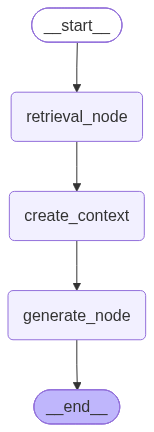

In [13]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [19]:
res=graph.invoke({"question":"What is his experience?"},
                 {"configurable":{"thread_id":"123"}})
print(res['answer'])

His experience includes:

*   **AI/ML Engineer at DevMatrix (Jun 2025 – Present):** Building applications using Large Language Models (LLMs), Retrieval-Augmented Generation (RAG), and Graph RAG.
*   **AI Data Trainer at Invisible Technologies (2022 – Present):** Evaluating, correcting, and ranking model-generated Python and technical responses; authoring reference solutions and structured critiques; and applying rubric-driven review standards.
*   **AI Trainer (Project-Based) at SuperAnnotate, SME Careers, and Alignerr:** Completing project-based assignments involving labeling, annotating, and evaluating model-generated outputs (specifically as a Data Science AI Trainer at SuperAnnotate) using proprietary annotation tools.
